# APS Failure at Scania Trucks

**Задача:** исследовать эксплуатационные данные грузовиков и выявить трудности прогноза отказа компонента пневматической системы APS.

**Источник:** [UCI APS Failure at Scania Trucks](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks), файлы `aps_failure_training_set.csv` и `aps_failure_test_set.csv`. Файлы должны лежать рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, типы, первые строки и основные статистики. Исходный CSV содержит служебный текст перед заголовком, поэтому чтение начинается с 21-й строки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("aps_failure_training_set.csv", skiprows=20, na_values=["na"])
X = df.drop(columns="class")
print("Размер:", df.shape, "Входных признаков:", X.shape[1])
print("Типы:", df.dtypes.value_counts().to_dict())
display(df[["class", "aa_000", "ab_000", "ag_005", "ba_000", "ck_000"]].head())

Размер: (60000, 171) Входных признаков: 170
Типы: {dtype('float64'): 169, <StringDtype(storage='python', na_value=nan)>: 1, dtype('int64'): 1}


,class,aa_000,ab_000,ag_005,ba_000,ck_000
0,neg,76698,NaN,1432864.0,2328746.0,916567.68
1,neg,33058,NaN,653294.0,1378576.0,643536.96
2,neg,41040,NaN,370592.0,790690.0,236099.52
3,neg,12,0.0,3232.0,6176.0,4525.44
4,neg,60874,NaN,1966618.0,1348578.0,379111.68


In [2]:
summary = df.describe(include="all").T
print("Строк в сводной статистике:", len(summary))
display(summary.loc[["class", "aa_000", "ab_000", "ag_005", "ba_000", "ck_000"]].round(2))

Строк в сводной статистике: 171


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
class,60000,2,neg,59000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aa_000,60000.0,NaN,NaN,NaN,59336.499567,145430.056532,0.0,834.0,30776.0,48668.0,2746564.0
ab_000,13671.0,NaN,NaN,NaN,0.713189,3.478962,0.0,0.0,0.0,0.0,204.0
ag_005,59329.0,NaN,NaN,NaN,1108373.830269,3262607.273818,0.0,13834.0,176020.0,913964.0,179187978.0
ba_000,59312.0,NaN,NaN,NaN,1399651.956636,3777091.37326,0.0,33478.5,679486.0,1276368.0,232871714.0
ck_000,59662.0,NaN,NaN,NaN,714342.701852,2180714.298391,0.0,14586.72,250267.2,549352.32,55428669.12


Обучающая часть содержит 60 000 записей, 170 входных признаков и таргет `class`. Названия числовых признаков неизвестны. По описанию UCI в них представлены счётчики и интервалы гистограмм, точный физический смысл отдельных столбцов не раскрыт.

## 2. Таргет

Доли классов и цена ошибок согласно описанию UCI.

Количество:
class
neg    59000
pos     1000
Name: count, dtype: int64
Доли, %:
class
neg    98.33
pos     1.67
Name: count, dtype: float64


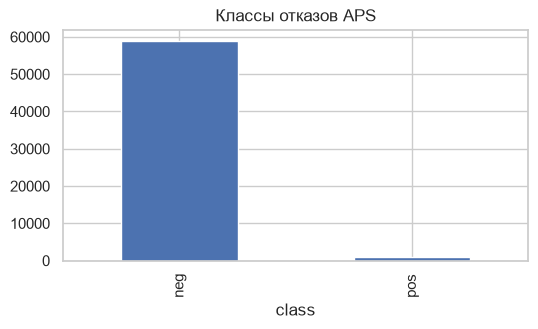

Всегда neg - стоимость: 500000
Всегда pos - стоимость: 590000
Цена FN / FP: 50.0


In [3]:
counts = df["class"].value_counts().reindex(["neg", "pos"])
print("Количество:")
print(counts)
print("Доли, %:")
print((counts / len(df) * 100).round(2))
counts.plot.bar(figsize=(6, 3))
plt.title("Классы отказов APS")
plt.xlabel("class")
plt.show()
print("Всегда neg - стоимость:", counts["pos"] * 500)
print("Всегда pos - стоимость:", counts["neg"] * 10)
print("Цена FN / FP:", 500 / 10)

Положительный класс `pos` редок. В описании UCI стоимость пропущенного отказа (FN) равна 500, а ненужной проверки (FP) - 10. Поэтому одной accuracy недостаточно для выбора модели.

## 3. Пропуски

Символ `na` из CSV распознан как `NaN`. Проверяются все признаки, число неполных строк и различия по классам.

In [4]:
missing = X.isna().sum()
row_missing = X.isna().sum(axis=1)
print("Всего NaN во входных признаках:", int(missing.sum()))
print("Доля ячеек, %:", round(100 * missing.sum() / X.size, 2))
print("Признаков с NaN:", int(missing.gt(0).sum()))
print("Признаков с >=50% NaN:", int(missing.ge(len(df) * .5).sum()))
print("Строк с >=1 NaN:", int(row_missing.gt(0).sum()))
print("Полностью заполненных строк:", int(row_missing.eq(0).sum()))
display(pd.DataFrame({"NaN": missing, "NaN, %": 100 * missing / len(df)}).sort_values("NaN", ascending=False).head(12).round(2))

Всего NaN во входных признаках: 850015
Доля ячеек, %: 8.33
Признаков с NaN: 169
Признаков с >=50% NaN: 8
Строк с >=1 NaN: 59409
Полностью заполненных строк: 591


,NaN,"NaN, %"
br_000,49264,82.11
bq_000,48722,81.20
bp_000,47740,79.57
bo_000,46333,77.22
ab_000,46329,77.22
cr_000,46329,77.22
bn_000,44009,73.35
bm_000,39549,65.92
bl_000,27277,45.46
bk_000,23034,38.39


In [5]:
print("Пропуски в строке:")
print(row_missing.describe(percentiles=[.5, .9, .95, .99]).round(2))
missing_by_class = pd.DataFrame({"class": df["class"], "NaN в строке": row_missing})
display(missing_by_class.groupby("class")["NaN в строке"].agg(["mean", "median"]).round(2))
for col in ["br_000", "bq_000", "ab_000", "aa_000"]:
    print(col, "NaN по классам, %:",
          (df.groupby("class")[col].apply(lambda s: 100 * s.isna().mean())).round(2).to_dict())

Пропуски в строке:
count    60000.00
mean        14.17
std         16.10
min          0.00
50%          8.00
90%         24.00
95%         48.00
99%         80.00
max        168.00
dtype: float64


,mean,median
class,,
neg,13.91,8.0
pos,29.15,20.5


br_000 NaN по классам, %: {'neg': 83.35, 'pos': 9.0}
bq_000 NaN по классам, %: {'neg': 82.43, 'pos': 8.7}
ab_000 NaN по классам, %: {'neg': 77.22, 'pos': 77.1}
aa_000 NaN по классам, %: {'neg': 0.0, 'pos': 0.0}


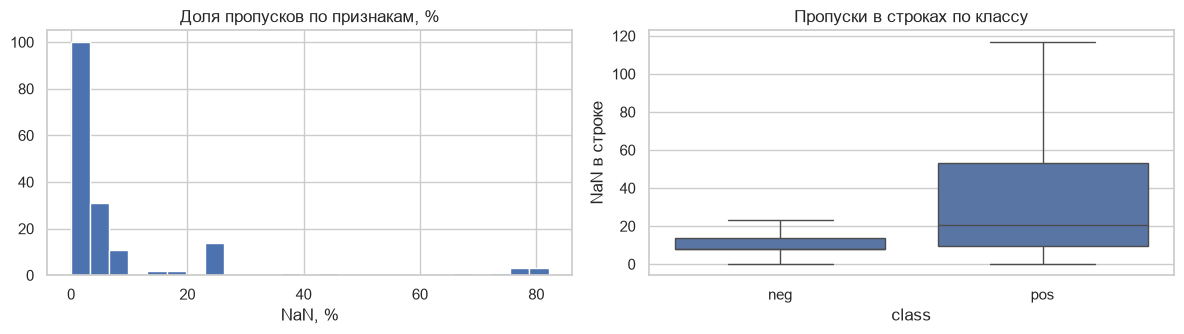

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
(100 * missing / len(df)).hist(bins=25, ax=axes[0])
axes[0].set_title("Доля пропусков по признакам, %")
axes[0].set_xlabel("NaN, %")
sns.boxplot(data=missing_by_class, x="class", y="NaN в строке", ax=axes[1], showfliers=False)
axes[1].set_title("Пропуски в строках по классу")
plt.tight_layout()
plt.show()

Пропуски распределены неодинаково: часть признаков почти заполнена, другие отсутствуют в большинстве строк. У `pos` среднее число пропусков в строке больше, чем у `neg`. Для некоторых столбцов доли пропусков по классам сильно различаются.

## 4. Дубликаты, постоянные значения и диапазоны

Проверяются полные дубликаты, повторяющиеся векторы признаков и столбцы без изменяющихся наблюдаемых значений.

In [7]:
print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов входных признаков:", X.duplicated().sum())
unique = X.nunique(dropna=True)
print("Признаков с <=1 различным значением:", unique.le(1).sum())
print("Их названия:", unique[unique.le(1)].index.tolist())
print("Признаков с отрицательными наблюдаемыми значениями:", X.min().lt(0).sum())
print("Постоянное значение cd_000:", X["cd_000"].dropna().unique())
print("Отсутствующих значений cd_000:", X["cd_000"].isna().sum())

Полных дубликатов: 0
Дубликатов входных признаков: 0
Признаков с <=1 различным значением: 1
Их названия: ['cd_000']
Признаков с отрицательными наблюдаемыми значениями: 0
Постоянное значение cd_000: [1209600.]
Отсутствующих значений cd_000: 676


Дубликаты не обнаружены. `cd_000` имеет единственное наблюдаемое значение и отдельные пропуски. Отрицательных чисел в исходных признаках нет; это не подтверждает корректность всех показаний без их расшифровки.

## 5. Числовые распределения и IQR

Показаны четыре обезличенных признака с разными масштабами. Логарифм используется только для графиков, исходный `df` не изменяется.

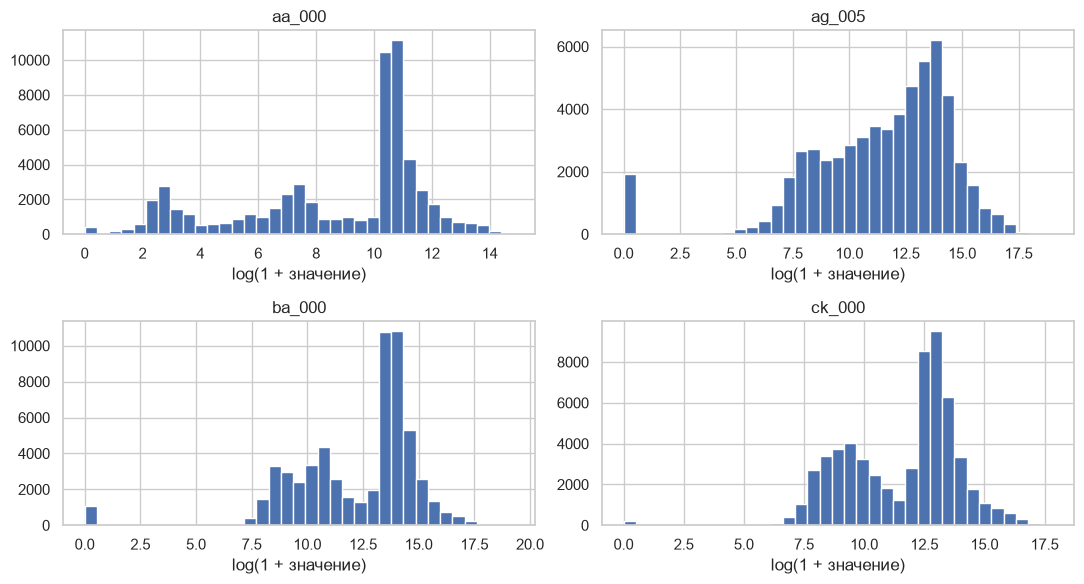

In [9]:
examples = ["aa_000", "ag_005", "ba_000", "ck_000"]
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for col, ax in zip(examples, axes.flat):
    np.log1p(X[col].dropna()).hist(bins=35, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("log(1 + значение)")
plt.tight_layout()
plt.show()

In [10]:
for col in examples:
    s = X[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    flagged = s.lt(q1 - 1.5 * iqr) | s.gt(q3 + 1.5 * iqr)
    print(col, "IQR-сигналы:", int(flagged.sum()),
          f"({100 * flagged.mean():.2f}% заполненных строк)",
          "медиана:", round(s.median(), 2))

aa_000 IQR-сигналы: 5627 (9.38% заполненных строк) медиана: 30776.0
ag_005 IQR-сигналы: 5946 (10.02% заполненных строк) медиана: 176020.0
ba_000 IQR-сигналы: 4918 (8.29% заполненных строк) медиана: 679486.0
ck_000 IQR-сигналы: 5551 (9.30% заполненных строк) медиана: 250267.2


Значения имеют длинные правые хвосты. IQR отмечает необычно большие наблюдения, но без физического описания датчиков их нельзя считать ошибками и удалять автоматически.

## 6. Группы гистограмм

По документации UCI часть признаков объединена в группы интервалов с одинаковыми префиксами.

In [11]:
prefix_counts = pd.Series([col.split("_")[0] for col in X.columns]).value_counts()
hist_groups = prefix_counts[prefix_counts.eq(10)].sort_index()
print("Групп по 10 столбцов:", len(hist_groups))
display(pd.DataFrame({"Столбцов": hist_groups,
    "Средняя доля NaN, %": [round(100 * X[[c for c in X if c.startswith(p + "_")]].isna().to_numpy().mean(), 2)
                            for p in hist_groups.index]}))

Групп по 10 столбцов: 7


,Столбцов,"Средняя доля NaN, %"
ag,10,1.12
ay,10,1.12
az,10,1.12
ba,10,1.15
cn,10,1.14
cs,10,1.12
ee,10,1.12


Группы с общими префиксами нужно рассматривать как связанные измерения. Их значения не обозначают независимые прикладные характеристики с известным смыслом.

## 7. Связь с таргетом

Медианы выбранных признаков и доли пропусков по классам.

In [12]:
display(df.groupby("class")[examples].agg("median").round(2))
print("Пропуски выбранных признаков по классам, %:")
display(df.groupby("class")[examples].agg(lambda s: 100 * s.isna().mean()).round(2))

,aa_000,ag_005,ba_000,ck_000
class,,,,
neg,30416.0,165806.0,663991.0,242316.48
pos,584994.0,9476568.0,10972571.0,6848688.48


Пропуски выбранных признаков по классам, %:


,aa_000,ag_005,ba_000,ck_000
class,,,,
neg,0.0,1.13,1.16,0.56
pos,0.0,0.40,0.40,1.00


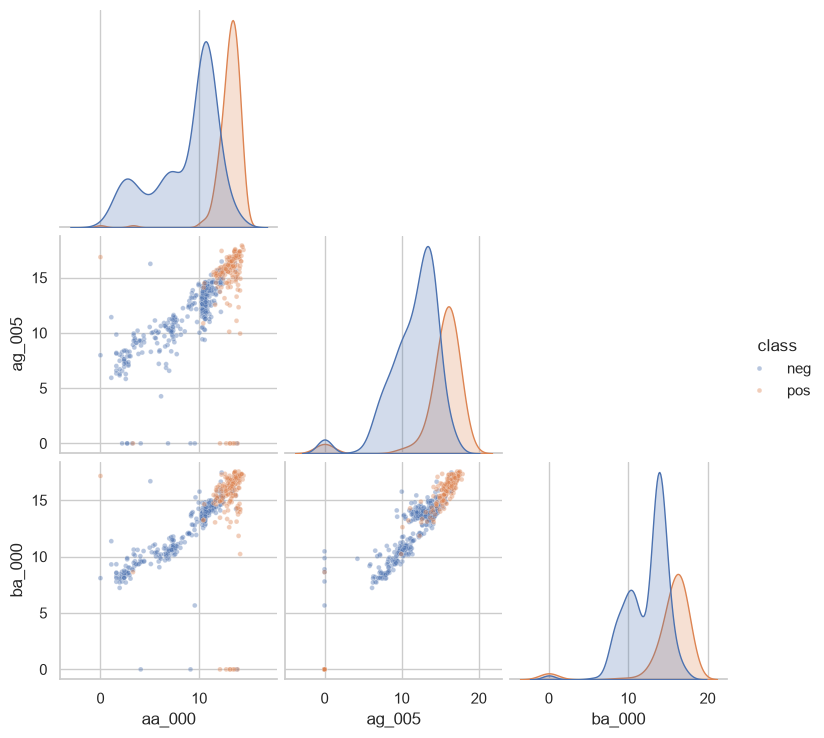

In [13]:
shown = pd.concat([
    df.loc[df["class"].eq("neg")].sample(350, random_state=42),
    df.loc[df["class"].eq("pos")].sample(175, random_state=42)
])[["class", "aa_000", "ag_005", "ba_000"]].copy()
for col in ["aa_000", "ag_005", "ba_000"]:
    shown[col] = np.log1p(shown[col])
sns.pairplot(shown, vars=["aa_000", "ag_005", "ba_000"],
             hue="class", corner=True, plot_kws={"alpha": .4, "s": 12})
plt.show()

Медианы выбранных признаков у `pos` выше, чем у `neg`. В `pairplot` классы намеренно представлены не в исходной пропорции, поэтому график показывает распределения, но не частоты классов.

## 8. Корреляции

Выводятся признаки с наибольшей по модулю линейной связью с бинарным таргетом. Постоянные столбцы и признаки с долей пропусков выше 10% исключены только из этого расчёта корреляций.

Признаков в расчёте: 141


ci_000    0.553
bb_000    0.543
bv_000    0.542
bu_000    0.542
cq_000    0.542
bt_000    0.537
aa_000    0.537
aq_000    0.531
bj_000    0.525
ah_000    0.525
Name: r с pos, dtype: float64

aa_000 / ci_000: 0.965


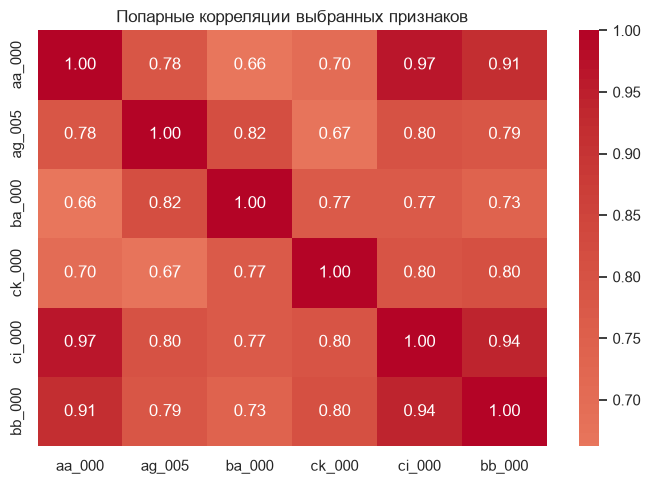

In [14]:
candidates = [col for col in X if X[col].notna().mean() >= .9 and X[col].nunique(dropna=True) > 1]
y_num = df["class"].eq("pos").astype(int)
target_corr = X[candidates].corrwith(y_num).dropna()
print("Признаков в расчёте:", len(candidates))
display(target_corr.sort_values(key=lambda s: s.abs(), ascending=False).head(10).round(3).rename("r с pos"))
print("aa_000 / ci_000:", round(X["aa_000"].corr(X["ci_000"]), 3))
corr_cols = ["aa_000", "ag_005", "ba_000", "ck_000", "ci_000", "bb_000"]
plt.figure(figsize=(7, 5))
sns.heatmap(X[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Попарные корреляции выбранных признаков")
plt.tight_layout()
plt.show()

У некоторых обезличенных признаков выражена линейная связь с таргетом. Между отдельными входными столбцами тоже есть высокая корреляция. Это статистические зависимости.

## 9. Официальное тестовое разбиение

Проверяются только размер и соответствие схемы официального тестового файла. Распределения и значения таргета тестовой части не исследуются.

In [15]:
test = pd.read_csv("aps_failure_test_set.csv", skiprows=20, na_values=["na"])
print("Обучающая часть:", df.shape)
print("Тестовая часть:", test.shape)
print("Порядок и названия столбцов совпадают:", df.columns.equals(test.columns))

Обучающая часть: (60000, 171)
Тестовая часть: (16000, 171)
Порядок и названия столбцов совпадают: True


Официальная тестовая часть отделена от анализа обучающих данных. В файлах нет явной временной метки, позволяющей проверить, соответствует ли разбиение будущему периоду.

## 10. Выводы и эталон для агента

1. **Цель:** `class`, обнаружение отказа APS (`pos` / `neg`). Постановка - бинарная классификация.
2. **Дисбаланс:** класс `pos` редок; одной accuracy недостаточно.
3. **Пропуски:** `na` превращается в `NaN`; степень заполненности различается между признаками и классами.
4. **Проверка данных:** `cd_000` почти постоянен; встречаются асимметричные числовые распределения, IQR не задаёт правило удаления.
5. **Структура:** имена признаков анонимизированы; семь групп по десять интервалов относятся к гистограммам.
6. **Метрика:** учитывать разные цены FP и FN согласно документации UCI; дополнительно полезны recall и precision для `pos`.
7. **Валидация:** сохранять официальный тест отдельно; без временных меток нельзя объявлять разбиение хронологическим.